# Calificaciones, escala maestra y la PD a través del ciclo de un grado

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** los cuadernos 01 a 04 del tema 01 (el motor, un artefacto, una primera prueba)
- **Tiempo de lectura:** unos 30 minutos

## Objetivos

Al terminar este cuaderno puedes:

- leer la tabla de cohortes de una agencia calificadora: los grados, el estado de incumplimiento, las calificaciones retiradas y el tamaño de la cohorte;
- convertir los conteos de un año en una PD a un año por grado con el estimador de cohorte del motor, y decir qué pasa con las calificaciones retiradas;
- explicar por qué la PD de un año es un número en un punto del tiempo y el promedio de muchos años es el número a través del ciclo que necesita la escala maestra;
- unir ambos con el modelo de un factor (Merton-Vasicek), leyendo el factor del ciclo crediticio que implica cada año;
- comparar cada recálculo con el artefacto versionado, nombrando la versión del motor que lo calculó.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.engines import vasicek
from riskvalidation.regulatory import irb
from riskvalidation.transitions import estimators, ttc

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son el caso C04 de Contraste, la variante S&P, tal como el producto la versiona. La fuente es la publicación CEREP de ESMA, el registro donde las agencias calificadoras reportan sus calificaciones y sus transiciones (clase de licencia `mirror-allowed`, atribución en el artefacto: "Source: ESMA CEREP; tables transformed by Contraste"; https://registers.esma.europa.eu/cerep-publication/). El pipeline tomó las calificaciones corporativas de largo plazo de la entidad europea de S&P por categoría, las llevó a **siete grados vigentes** (AAA, AA, A, BBB, BB, B, CCC-C) más **incumplimiento**, y guardó una tabla por **cohorte** anual: las calificaciones vigentes el 1 de enero y dónde estaba cada una el 31 de diciembre.

- **Archivo que se lee:** `data/derived/C04/sp.json`, las claves `outputs.cohorts` (26 cohortes anuales), `outputs.pd` (la PD a un año por cohorte y grado bajo cuatro definiciones), `outputs.lra` (los promedios de largo plazo), `outputs.pooled` y `outputs.origination` (la matriz agrupada y la mezcla de cohortes).
- **La definición importa.** CEREP declara que "no deterministic definition of a default event has been set up" (no se fijó una definición determinista de evento de incumplimiento), así que cada PD nombra su página. Este cuaderno usa `d4`, la PD leída de la página de transiciones (la columna de incumplimiento sobre la cohorte menos sus retiros), el tratamiento estándar de la industria. El cuaderno 10 de este tema muestra cuánto mueve una PD la elección de la página.

La celda siguiente carga el artefacto e imprime lo que contiene.

In [2]:
# Cargar el artefacto (el cuaderno está tres carpetas bajo la raíz del repositorio) e imprimir lo que contiene
ROOT = Path("../../..").resolve()
sp = json.loads((ROOT / "data" / "derived" / "C04" / "sp.json").read_text(encoding="utf-8"))
out = sp["outputs"]
grades, states = out["grades"], out["states"]

print("agencia:", out["agency"]["name"])
print("atribución:", out["attribution"])
print("calculado con riskvalidation", sp["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)
print("grados:", grades)
print("estados:", states)
print("cohortes anuales:", len(out["cohorts"]), "desde", out["cohorts"][0]["label"], "hasta", out["cohorts"][-1]["label"])

agencia: Standard & Poor's Credit Market Services Europe Limited
atribución: Source: ESMA CEREP; tables transformed by Contraste
calculado con riskvalidation 0.4.3 | instalado 0.8.1
grados: ['AAA', 'AA', 'A', 'BBB', 'BB', 'B', 'CCC-C']
estados: ['AAA', 'AA', 'A', 'BBB', 'BB', 'B', 'CCC-C', 'D']
cohortes anuales: 26 desde 2000 hasta 2025


**Una cohorte.** Cada registro de cohorte guarda, para las calificaciones vigentes al inicio del año, el `size` por grado, los `counts` de dónde estaban al final (filas el grado al inicio, columnas los siete grados y el incumplimiento) y las calificaciones `withdrawn` (retiradas): las que la agencia dejó de calificar durante el año y cuyo estado final se desconoce. La celda siguiente imprime la cohorte 2000 como tabla y verifica que los conteos y las retiradas suman el tamaño de la cohorte.

In [3]:
# Imprimir la cohorte 2000: los conteos por grado inicial (filas) y estado final (columnas), las retiradas y el tamaño
c2000 = out["cohorts"][0]
counts = np.array(c2000["counts"], dtype=float)
withdrawn = np.array(c2000["withdrawn"], dtype=float)
size = np.array(c2000["size"], dtype=float)

print("cohorte", c2000["label"], c2000["begin"], "a", c2000["end"])
print(f"{'':8s}" + "".join(f"{s:>7s}" for s in states) + f"{'retiradas':>12s}{'tamaño':>8s}")
for g, row, w, n in zip(grades, counts, withdrawn, size):
    print(f"{g:8s}" + "".join(f"{v:7.0f}" for v in row) + f"{w:12.0f}{n:8.0f}")
print("los conteos más las retiradas igualan el tamaño en cada grado:", bool(np.allclose(counts.sum(axis=1) + withdrawn, size)))

cohorte 2000 2000-01-01 a 2000-12-31
            AAA     AA      A    BBB     BB      B  CCC-C      D   retiradas  tamaño
AAA         205     22      2      0      0      0      0      0          12     241
AA            5    776     67      4      0      0      0      0          71     923
A             0     55   1429    136      6      1      6      4         104    1741
BBB           1      6     65   1501     65      9      3      6          95    1751
BB            0      4      1     40    885     74      9      3          78    1094
B             0      5      3      5     47    791     47     53         119    1070
CCC-C         0      0      0      0      1     13     76     19          33     142
los conteos más las retiradas igualan el tamaño en cada grado: True


## Método

### Paso 1: la PD a un año de un grado desde una cohorte

El estimador de cohorte de Anderson y Goodman (1957, ecuaciones 2.8 y 2.9) estima la probabilidad de pasar del grado $i$ al estado $j$ en un año como la fracción de las calificaciones que partieron en $i$ y terminaron en $j$:

$$\hat p_{ij} = \frac{N_{ij}}{N_i}$$

con $N_i$ las calificaciones que partieron en $i$ y siguen observadas al final. La PD del grado $i$ es la entrada de la columna de incumplimiento, $\hat p_{i,D}$. Las retiradas no están en $N_i$: el estándar de la industria, "the method which has emerged as an industry standard" (el método que se ha impuesto como estándar de la industria; Schuermann y Hanson, 2004, nota 4), trata un retiro como no informativo y lo reparte entre los estados en proporción a sus valores, lo que equivale a quitarlo y dividir por lo que queda. El `cohort` del motor recibe una tabla cuadrada, así que la celda siguiente agrega una fila vacía de incumplimiento (el incumplimiento es absorbente) y lo llama con `treatment="exclude"`.

In [4]:
# Una llamada al estimador de cohorte del motor sobre la cohorte 2000, con las retiradas removidas
square = np.vstack([counts, np.zeros(len(states))])   # una fila vacía de incumplimiento hace cuadrada la tabla
withdrawn8 = np.append(withdrawn, 0.0)
m_exclude = estimators.cohort(square, withdrawn8, treatment="exclude")
p_exclude = m_exclude["matrix"]

print("calificaciones de cada grado inicial tras quitar las retiradas:", m_exclude["row_sizes"][:7].astype(int))
print("fracción retirada:", np.round(m_exclude["withdrawn_share"][:7], 4))
print("las filas suman uno:", bool(np.allclose(p_exclude.sum(axis=1), 1.0)))
print(f"{'':8s}" + "".join(f"{s:>9s}" for s in states))
for g, row in zip(grades, p_exclude[:7]):
    print(f"{g:8s}" + "".join(f"{v:9.4f}" for v in row))

calificaciones de cada grado inicial tras quitar las retiradas: [ 229  852 1637 1656 1016  951  109]
fracción retirada: [0.0498 0.0769 0.0597 0.0543 0.0713 0.1112 0.2324]
las filas suman uno: True
              AAA       AA        A      BBB       BB        B    CCC-C        D
AAA        0.8952   0.0961   0.0087   0.0000   0.0000   0.0000   0.0000   0.0000
AA         0.0059   0.9108   0.0786   0.0047   0.0000   0.0000   0.0000   0.0000
A          0.0000   0.0336   0.8729   0.0831   0.0037   0.0006   0.0037   0.0024
BBB        0.0006   0.0036   0.0393   0.9064   0.0393   0.0054   0.0018   0.0036
BB         0.0000   0.0039   0.0010   0.0394   0.8711   0.0728   0.0089   0.0030
B          0.0000   0.0053   0.0032   0.0053   0.0494   0.8318   0.0494   0.0557
CCC-C      0.0000   0.0000   0.0000   0.0000   0.0092   0.1193   0.6972   0.1743


La columna de incumplimiento de esa matriz es la PD a un año por grado de la cohorte 2000. El artefacto versiona la misma cantidad para cada cohorte en `outputs.pd.d4`, así que la celda siguiente compara el recálculo con la fila versionada e imprime la versión del motor que la calculó (el artefacto se calculó con un motor más antiguo que el instalado, y una diferencia se leería contra eso).

In [5]:
# Comparar la columna de incumplimiento del motor con la PD versionada de la cohorte 2000 (definición d4)
pd_engine = p_exclude[:7, -1]
pd_committed = np.array(out["pd"]["d4"][0], dtype=float)
print("calculado con riskvalidation", sp["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)
print(f"{'grado':8s}{'motor':>12s}{'versionada':>14s}")
for g, a, b in zip(grades, pd_engine, pd_committed):
    print(f"{g:8s}{a:12.6f}{b:14.6f}")
print("igual a la PD versionada:", bool(np.allclose(pd_engine, pd_committed, atol=1e-8)))

calculado con riskvalidation 0.4.3 | instalado 0.8.1
grado          motor    versionada
AAA         0.000000      0.000000
AA          0.000000      0.000000
A           0.002443      0.002443
BBB         0.003623      0.003623
BB          0.002953      0.002953
B           0.055731      0.055731
CCC-C       0.174312      0.174312
igual a la PD versionada: True


### Paso 2: qué hacen las calificaciones retiradas a una PD

Si un retiro no es informativo, quitarlo es inocuo. Si una calificación se retira porque el deudor está en problemas, quitarla subestima la PD. El otro tratamiento del motor, `treatment="state"`, mantiene las retiradas en el denominador como un noveno estado absorbente, que es como el párrafo 76 de EBA/GL/2017/16 mantiene las obligaciones cerradas en la muestra. La celda siguiente imprime ambas PD para la cohorte 2000. El cuaderno 10 mide el sesgo sobre trayectorias de calificación cuya verdad se conoce.

In [6]:
# La misma cohorte con las retiradas mantenidas como estado absorbente, junto a la remoción
m_state = estimators.cohort(square, withdrawn8, treatment="state")
pd_keep = m_state["matrix"][:7, len(states) - 1]
pd_keep_committed = np.array(out["pd"]["keep"][0], dtype=float)
print(f"{'grado':8s}{'quitadas (d4)':>20s}{'mantenidas (keep)':>24s}{'razón':>10s}")
for g, a, b in zip(grades, pd_engine, pd_keep):
    print(f"{g:8s}{a:20.6f}{b:24.6f}{(a / b if b > 0 else float('nan')):10.3f}")
print("igual a la columna keep versionada:", bool(np.allclose(pd_keep, pd_keep_committed, atol=1e-8)))

grado          quitadas (d4)       mantenidas (keep)     razón
AAA                 0.000000                0.000000       nan
AA                  0.000000                0.000000       nan
A                   0.002443                0.002298     1.064
BBB                 0.003623                0.003427     1.057
BB                  0.002953                0.002742     1.077
B                   0.055731                0.049533     1.125
CCC-C               0.174312                0.133803     1.303
igual a la columna keep versionada: True


### Paso 3: de un año a la PD a través del ciclo

La PD de un año es un número en un punto del tiempo: se mueve con la economía. La escala maestra de un sistema de calificación necesita la PD a través del ciclo (TTC) de cada grado, el nivel que el grado tiene en un ciclo completo. Las guías de la EBA (EBA/GL/2017/16, párrafo 84) la definen como el promedio de largo plazo de las tasas de incumplimiento a un año, "the observed average of the one-year default rates" (el promedio observado de las tasas de incumplimiento a un año) sobre las cohortes donde el grado tiene calificaciones:

$$\mathrm{LRA}_i = \frac{1}{T_i} \sum_{t=1}^{T_i} \hat p_{i,D}(t)$$

El artefacto guarda la PD a un año de cada cohorte en `outputs.pd.d4` (26 filas, una por año, siete grados) y el promedio en `outputs.lra.d4.rate`. La celda siguiente recalcula el promedio desde las tasas anuales, lo compara con el versionado e imprime, por grado, el año más bajo, el más alto y el último. Agrega la tasa agrupada (todos los incumplimientos sobre todas las calificaciones, de modo que las cohortes grandes pesan más) con su intervalo de Jeffreys del artefacto: el promedio de las tasas anuales y la tasa agrupada responden preguntas algo distintas.

In [7]:
# Promediar las tasas anuales de cada grado y comparar con el promedio de largo plazo (LRA) versionado
yearly = np.array([[np.nan if v is None else v for v in row] for row in out["pd"]["d4"]], dtype=float)   # 26 cohortes x 7 grados
years = [c["label"] for c in out["cohorts"]]
lra_here = np.nanmean(yearly, axis=0)
lra_committed = np.array(out["lra"]["d4"]["rate"], dtype=float)
pooled_rate = np.array(out["lra"]["d4"]["pooled_rate"], dtype=float)
jeffreys_low = np.array(out["lra"]["d4"]["jeffreys"]["lower"], dtype=float)
jeffreys_high = np.array(out["lra"]["d4"]["jeffreys"]["upper"], dtype=float)

print("calculado con riskvalidation", sp["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)
print(f"{'grado':8s}{'LRA':>10s}{'versionada':>12s}{'año mínimo':>16s}{'año máximo':>16s}{'último':>10s}{'tasa agrupada':>16s}{'intervalo 95% de la tasa agrupada (Jeffreys)':>48s}")
for g in range(7):
    lo, hi = int(np.nanargmin(yearly[:, g])), int(np.nanargmax(yearly[:, g]))
    interval = f"{jeffreys_low[g]:.5f} a {jeffreys_high[g]:.5f}"
    print(f"{grades[g]:8s}{lra_here[g]:10.5f}{lra_committed[g]:12.5f}{years[lo] + ' ' + format(yearly[lo, g], '.4f'):>16s}{years[hi] + ' ' + format(yearly[hi, g], '.4f'):>16s}{yearly[-1, g]:10.4f}{pooled_rate[g]:16.5f}{interval:>48s}")
print("el promedio iguala el LRA versionado:", bool(np.allclose(lra_here, lra_committed, atol=1e-8)))
print("la escala maestra sube con el grado:", bool(np.all(np.diff(lra_here) > 0)))

calculado con riskvalidation 0.4.3 | instalado 0.8.1
grado          LRA  versionada      año mínimo      año máximo    último   tasa agrupada    intervalo 95% de la tasa agrupada (Jeffreys)
AAA        0.00000     0.00000     2000 0.0000     2000 0.0000    0.0000         0.00000                               0.00000 a 0.00132
AA         0.00005     0.00005     2000 0.0000     2008 0.0013    0.0000         0.00005                               0.00001 a 0.00023
A          0.00030     0.00030     2003 0.0000     2001 0.0025    0.0000         0.00029                               0.00016 a 0.00048
BBB        0.00079     0.00079     2003 0.0000     2002 0.0053    0.0000         0.00082                               0.00058 a 0.00112
BB         0.00336     0.00336     2006 0.0000     2001 0.0216    0.0000         0.00346                               0.00279 a 0.00425
B          0.01330     0.01330     2007 0.0000     2000 0.0557    0.0054         0.01173                               0.0105

La figura dibuja la PD anual de los tres grados especulativos frente a su promedio de largo plazo. La tasa anual oscila alrededor de su promedio (nótense las escalas verticales distintas); la tabla anterior nombra el año más alto y el más bajo de cada grado. El promedio es el número que usa una escala maestra; la tasa anual es lo que reporta un sistema en un punto del tiempo.

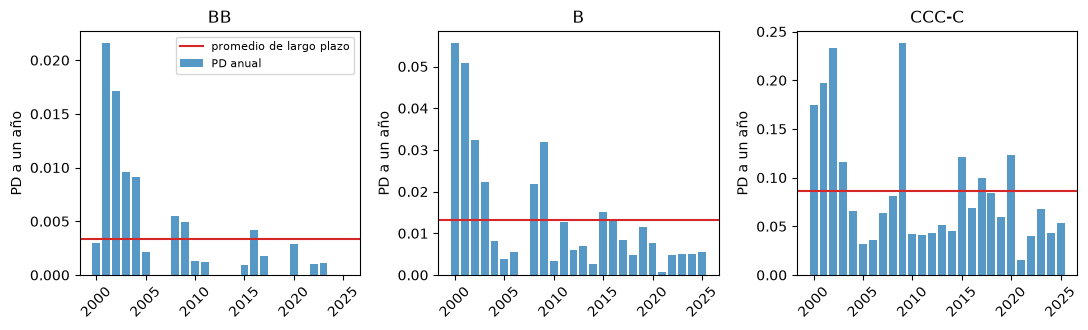

In [8]:
# Dibujar la PD anual a un año de BB, B y CCC-C con el promedio de largo plazo como línea
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, g in zip(axes, (4, 5, 6)):
    ax.bar(range(len(years)), yearly[:, g], color="tab:blue", alpha=0.75, label="PD anual")
    ax.axhline(lra_here[g], color="tab:red", label="promedio de largo plazo")
    ax.set_xticks(range(0, len(years), 5))
    ax.set_xticklabels(years[::5], rotation=45)
    ax.set_title(grades[g])
    ax.set_ylabel("PD a un año")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

### Paso 4: el vínculo entre ambas, el modelo de un factor

¿Por qué la tasa anual oscila alrededor del promedio? El modelo de Merton-Vasicek da a cada deudor un retorno de activos $A = \sqrt{\rho}\, Z + \sqrt{1-\rho}\, \varepsilon$, con un factor sistemático $Z$ compartido por todos los deudores (la economía) y uno idiosincrático $\varepsilon$; el deudor cae en incumplimiento cuando $A$ queda bajo $\Phi^{-1}(p)$, donde $p$ es la PD a través del ciclo. Dado el estado de la economía $Z = z$, la probabilidad de incumplimiento, la PD en un punto del tiempo, es

$$p_{\mathrm{PIT}}(z) = \Phi\!\left(\frac{\Phi^{-1}(p) - \sqrt{\rho}\, z}{\sqrt{1-\rho}}\right)$$

(Vasicek, 2002). Un $z$ bajo es un mal año. Invirtiendo la fórmula, una tasa de incumplimiento anual observada $\mathrm{DR}_t$ implica el factor $z_t = \bigl(\Phi^{-1}(p) - \sqrt{1-\rho}\,\Phi^{-1}(\mathrm{DR}_t)\bigr)/\sqrt{\rho}$: el índice del ciclo crediticio de ese año. El motor tiene ambos sentidos, `vasicek.conditional_pd` y `vasicek.implied_factor`. La correlación de activos $\rho$ es un supuesto: la celda siguiente toma el valor corporativo de Basilea III que da `irb.correlation` a la PD TTC del grado (es el valor de la fórmula IRB, no una estimación con estos datos). Se usa el grado B porque tiene incumplimientos en casi todos los años (la celda siguiente los cuenta); un año con tasa exactamente cero no implica ningún factor finito y se omite.

In [9]:
# Leer el factor del ciclo crediticio que implica cada año para el grado B y volver a la PD para verificar el viaje de ida y vuelta
g = 5                                                   # grado B
ttc_pd = float(lra_here[g])
rho = irb.correlation("corporate", ttc_pd)              # correlación de activos corporativa de Basilea III a la PD TTC
rate = yearly[:, g]
usable = np.isfinite(rate) & (rate > 0)

z = vasicek.implied_factor(rate[usable], ttc_pd, rho)
back = vasicek.conditional_pd(ttc_pd, rho, z)

print("PD TTC de B:", round(ttc_pd, 5), "| rho:", round(rho, 4))
print("años con tasa de incumplimiento sobre cero:", int(usable.sum()), "de", len(years))
print("el viaje de ida y vuelta iguala la tasa observada:", bool(np.allclose(back, rate[usable])))
order = np.argsort(z)
used_years = [yr for yr, ok in zip(years, usable) if ok]
print("cinco peores años (factor más bajo):", [(used_years[k], round(float(z[k]), 2)) for k in order[:5]])
print("cinco mejores años (factor más alto):", [(used_years[k], round(float(z[k]), 2)) for k in order[::-1][:5]])
print("media del factor en los años usados (normal estándar en teoría):", round(float(z.mean()), 3))

PD TTC de B: 0.0133 | rho: 0.1817
años con tasa de incumplimiento sobre cero: 25 de 26
el viaje de ida y vuelta iguala la tasa observada: True
cinco peores años (factor más bajo): [('2000', -1.82), ('2001', -1.73), ('2002', -1.28), ('2009', -1.27), ('2003', -0.94)]
cinco mejores años (factor más alto): [('2021', 1.62), ('2014', 0.7), ('2010', 0.54), ('2005', 0.47), ('2018', 0.31)]
media del factor en los años usados (normal estándar en teoría): -0.209


La figura muestra el factor que el modelo lee de la tasa de incumplimiento del grado B cada año. Las barras bajo cero son los años peores que el ciclo promedio.

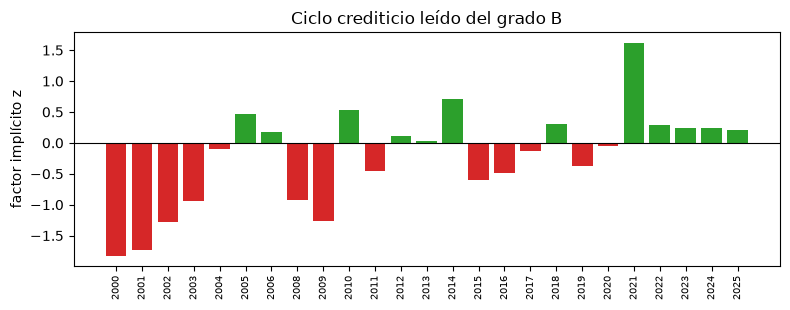

In [10]:
# Dibujar el factor del ciclo crediticio implicado por la tasa de incumplimiento anual del grado B
fig, ax = plt.subplots(figsize=(8, 3.2))
colors = ["tab:red" if v < 0 else "tab:green" for v in z]
ax.bar(range(len(z)), z, color=colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(range(len(z)))
ax.set_xticklabels(used_years, rotation=90, fontsize=7)
ax.set_ylabel("factor implícito z")
ax.set_title("Ciclo crediticio leído del grado B")
fig.tight_layout()
plt.show()

### Paso 5: el portafolio TTC de la matriz agrupada

Una matriz da la PD TTC de una segunda manera. Si el portafolio se propaga año tras año con la matriz anual agrupada, con su parte en incumplimiento castigada y reoriginada con la mezcla de cohortes observada, converge a un solo portafolio, el portafolio a través del ciclo $W_{\mathrm{ttc}}$ de Engelmann (2024), cuya tasa de incumplimiento es $W_{\mathrm{ttc}}' T V_w$ (con $V_w$ la columna de incumplimiento). El `ttc_portfolio` del motor itera ese mapa. El artefacto versiona la matriz agrupada (`outputs.pooled.matrix`, retiradas removidas), la mezcla de origen (`outputs.origination`) y la tasa de incumplimiento del resultado (`impact.ttc_default_rate`) junto a la tasa de incumplimiento de la mezcla de la última cohorte. La celda siguiente la recalcula. El cuaderno 07 desarrolla la fórmula y su deriva.

In [11]:
# Iterar el portafolio TTC de la matriz agrupada con la mezcla de cohortes observada y comparar con las tasas versionadas
pooled = np.array(out["pooled"]["matrix"], dtype=float)
origination = np.array(out["origination"], dtype=float)
result = ttc.ttc_portfolio(pooled, origination)

print("iteraciones:", result["iterations"], "| convergió:", result["converged"])
print(f"{'':8s}" + "".join(f"{s:>8s}" for s in states))
print(f"{'portafolio TTC':8s}" + "".join(f"{v:8.4f}" for v in result["portfolio"]))
print("tasa de incumplimiento del portafolio TTC:", round(result["default_rate"], 6), "| versionada:", round(sp["impact"]["ttc_default_rate"]["value"], 6))
print("tasa de incumplimiento de la mezcla de la última cohorte:", round(sp["impact"]["latest_default_rate"]["value"], 6))
print("igual a la tasa versionada:", bool(np.isclose(result["default_rate"], sp["impact"]["ttc_default_rate"]["value"], atol=1e-8)))

iteraciones: 697 | convergió: True
             AAA      AA       A     BBB      BB       B   CCC-C       D
portafolio TTC  0.0013  0.0519  0.2865  0.3039  0.1541  0.1608  0.0415  0.0000
tasa de incumplimiento del portafolio TTC: 0.006097 | versionada: 0.006097
tasa de incumplimiento de la mezcla de la última cohorte: 0.0077
igual a la tasa versionada: True


## Resultados

- **Un año, una cohorte.** El estimador de cohorte del motor convierte los conteos de 2000 en una PD a un año por grado e iguala la fila versionada de `outputs.pd.d4` a 1e-8 (el artefacto se calculó con riskvalidation 0.4.3, el cuaderno corre 0.8.1, y nada se movió). En esa cohorte el grado B tuvo una PD de 5,57% y CCC-C de 17,43%.
- **Las calificaciones retiradas mueven la PD.** Quitarlas es el tratamiento de la industria; mantenerlas como estado absorbente baja la PD de B en 2000 a 4,95% y la de CCC-C a 13,38%, porque el 11,1% de las calificaciones B y el 23,2% de las CCC-C se retiraron dentro del año. Que un retiro no diga nada del deudor es un supuesto; el cuaderno 10 lo pone a prueba.
- **Un año no es una PD de escala maestra.** La PD anual de B va de 0 (alcanzado primero en 2007) a 5,57% (2000) alrededor de un promedio de largo plazo de 1,33%; la de CCC-C, de 1,58% (2021) a 23,86% (2009) alrededor de 8,61%. Los siete promedios suben con el grado (0 para AAA, 0,005% para AA, 0,030% para A, 0,079% para BBB, 0,34% para BB, 1,33% para B, 8,61% para CCC-C) e igualan el `outputs.lra.d4.rate` versionado.
- **El ciclo se puede leer.** Con la correlación corporativa de Basilea III (un supuesto, 0,18 a la PD de B), la tasa de incumplimiento anual del grado B implica un factor del ciclo crediticio cuyos años más bajos son 2000, 2001, 2002, 2009 y 2003. La media de los 25 factores usables es -0,21, no el 0 de una normal estándar: 26 años desde 2000 son una muestra pequeña de un ciclo, y la correlación es un supuesto, así que lee el factor como un índice, no como una medición.
- **Una segunda ruta al mismo nivel.** Iterar la matriz agrupada con la mezcla de cohortes observada da un portafolio TTC cuya tasa de incumplimiento es 0,61%, igual al valor versionado, frente a 0,77% para la mezcla de la última cohorte.

Lo que este cuaderno no muestra: en qué se diferencian los estimadores de cohorte, de duración y de Aalen-Johansen (cuaderno 02), si una matriz anual describe a una cohorte durante varios años (cuaderno 04), ni cómo una PD se vuelve capital (cuaderno 07).

## Resumen

- La tabla de cohortes de una agencia da, por grado, dónde estaban las calificaciones un año después; la fracción que terminó en incumplimiento, sobre las calificaciones aún observadas, es la PD a un año del grado.
- Las calificaciones retiradas se quitan en el tratamiento de la industria y se mantienen en la lectura del párrafo 76 de la EBA; ambas difieren más en los grados más débiles.
- Una escala maestra necesita la PD a través del ciclo, el promedio de muchas tasas anuales; el modelo de un factor une ambas y lee un factor del ciclo crediticio de cada año.
- Cada recálculo se compara con el artefacto versionado solo después de nombrar la versión del motor que lo calculó.

**Qué probar después.** Cambia el grado del Paso 4 de B a BB y compara los peores años; luego lee el cuaderno 02 y sigue con el estimador de duración.

## Referencias

- ESMA, CEREP publication of credit rating agency ratings and transitions, with the help file ESMA65-8-10634. https://registers.esma.europa.eu/cerep-publication/
- Anderson, T. W. and Goodman, L. A. (1957), Statistical inference about Markov chains, Annals of Mathematical Statistics 28(1), equations 2.8 and 2.9. https://doi.org/10.1214/aoms/1177707039
- Schuermann, T. and Hanson, S. (2004), Estimating probabilities of default, FRBNY Staff Report 190, footnote 4. https://www.newyorkfed.org/medialibrary/media/research/staff_reports/sr190.pdf
- EBA (2017), Guidelines on PD estimation, LGD estimation and the treatment of defaulted exposures, EBA/GL/2017/16, paragraphs 76, 84 and 86.
- Vasicek, O. (2002), Loan portfolio value, Risk, December 2002, 160-162.
- Engelmann, B. (2024), Spurious default probability projections in credit risk stress testing models, arXiv 2401.08892.